# 1. Préparation et exploration des données

**Projet :** incendies de forêt en PACA, délais d'accès des sapeurs-pompiers.

Ce premier notebook :
1. charge les 4 sources de données ;
2. les explore (aperçu, valeurs manquantes) ;
3. les prépare (filtre PACA, casernes, forêts) ;
4. produit les statistiques descriptives des incendies, des casernes et des forêts ;
5. enregistre les données préparées pour le notebook 2.

**Données :**
- Communes : `entites-administratives.shp`
- Forêts : `occupation-du-sol-region-sud-2019Polygon.shp` (polygones dont `exo_19 = "BD FORET"`)
- Casernes : `casernes_osm.geojson` (OpenStreetMap, `amenity=fire_station`, extrait avec Overpass Turbo)
- Incendies : `Incendies.csv` (BDIFF, feux de forêt 2016-2025)

> **Pourquoi pas les fichiers « OSM Urgence » de DataSud ?** Ils ne contiennent que les objets OSM marqués avec la clé `emergency` (bouches incendie, défibrillateurs…). Une caserne est marquée `amenity=fire_station` : elle n'y figure pas. Nous avons donc extrait les casernes avec Overpass Turbo :
> ```
> [out:json][timeout:90];
> nwr["amenity"="fire_station"](42.9,4.1,45.2,7.8);
> out center;
> ```

## 0. Mise en place

In [10]:
import os
import sys

# je cherche la racine du projet (le dossier qui contient "modules")
racine_projet = None
for essai in [".", "..", "../.."]:
    if os.path.exists(os.path.join(essai, "modules")) and racine_projet is None:
        racine_projet = os.path.abspath(essai)
print("Racine du projet :", racine_projet)

# j'ajoute la racine aux endroits où Python cherche les modules
if racine_projet not in sys.path:
    sys.path.append(racine_projet)

# si je modifie un module, il est rechargé automatiquement
%load_ext autoreload
%autoreload 2

Racine du projet : c:\Users\User\Documents\Python\Groupe_KC_AHA_Python
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
import pandas as pd
import geopandas as gpd

from modules.intern.ats import parametres as p
from modules.intern.ats import chargement, preparation, graphiques

os.makedirs("sorties", exist_ok=True)

## 1. Chargement des données

In [12]:
dossier_donnees = chargement.trouver_dossier("Data")

chargement.telecharger_et_dezipper(p.URL_FORETS, os.path.join(dossier_donnees, "forests"), p.FICHIER_FORETS)
chemin_communes = chargement.trouver_fichier(p.FICHIER_COMMUNES, dossier_donnees)
chemin_forets = chargement.trouver_fichier(p.FICHIER_FORETS, dossier_donnees)
chemin_incendies = chargement.trouver_fichier(p.FICHIER_INCENDIES, dossier_donnees)
chemin_casernes = chargement.trouver_fichier(p.FICHIER_CASERNES, dossier_donnees)

df_admin = chargement.charger_couche(chemin_communes, encodage="utf-8")
df_casernes_osm = chargement.charger_couche(chemin_casernes)
df_incendies = chargement.charger_incendies(chemin_incendies)
# exo_19 = BD FORET : pour lire seulement les forêts
df_ocsol = chargement.charger_couche(chemin_forets, filtre="exo_19 = 'BD FORET'")


Téléchargement de https://minio.lab.sspcloud.fr/khcoulibaly/diffusion/occupation_du_sol.zip


## 2. Premier coup d'œil sur les données

In [13]:
chargement.apercu(df_admin, "Entités administratives")
chargement.apercu(df_casernes_osm, "Casernes OSM")
chargement.apercu(df_incendies, "Incendies (France entière)")
chargement.apercu(df_ocsol, "Occupation du sol (niveau 1 = 3)")

===== Entités administratives =====
Lignes : 1005 | Colonnes : 5
Colonnes : ['gid', 'type', 'nom', 'code', 'geometry']
Valeurs manquantes :
nom     1
code    1
dtype: int64

===== Casernes OSM =====
Lignes : 655 | Colonnes : 88
Colonnes : ['id', '@id', 'addr:city', 'addr:country', 'addr:full', 'addr:housename', 'addr:housenumber', 'addr:place', 'addr:postcode', 'addr:street', 'aeroway', 'alt_name', 'amenity', 'barrier', 'building', 'building:colour', 'building:levels', 'building:material', 'check_date', 'contact:city', 'contact:fax', 'contact:housenumber', 'contact:phone', 'contact:postcode', 'contact:street', 'contact:website', 'description', 'diff:ref:FR:RNB', 'email', 'emergency', 'end_date', 'fax', 'fire_station:type:FR', 'fixme', 'government', 'height', 'landuse', 'level', 'military', 'name', 'name:en', 'name:oc', 'not:operator:wikidata', 'note', 'official_name', 'old_name', 'opening_date', 'opening_hours', 'operator', 'operator:oc', 'operator:phone', 'operator:type', 'operator:wi

In [14]:
df_incendies.head()

,Année,Numéro,Département,Code INSEE,Nom de la commune,Date de première alerte,Surface parcourue (m2),Surface forêt (m2),Surface maquis garrigues (m2),Autres surfaces naturelles hors forêt (m2),...,Surfaces non boisées artificialisées (m2),Surfaces non boisées (m2),Précision des surfaces,Type de peuplement,Nature,Décès ou bâtiments touchés,Nombre de décès,Nombre de bâtiments totalement détruits,Nombre de bâtiments partiellement détruits,Précision de la donnée
0,2016,4608,66,66225,Villelongue-dels-Monts,2016-01-01 15:37:00,10,10.0,NaN,NaN,...,NaN,NaN,NaN,3.0,Involontaire (particulier),NaN,NaN,NaN,NaN,NaN
1,2016,6821,66,66026,Brouilla,2016-01-02 11:56:00,10000,10000.0,0.0,NaN,...,NaN,NaN,NaN,2.0,Involontaire (travaux),NaN,NaN,NaN,NaN,NaN
2,2016,12337,66,66106,Maureillas-las-Illas,2016-01-04 13:30:00,20,NaN,20.0,NaN,...,NaN,NaN,NaN,4.0,Malveillance,NaN,NaN,NaN,NaN,NaN
3,2016,6,974,97424,Cilaos,2016-01-05 16:05:00,800,0.0,NaN,800.0,...,0.0,0.0,Estimées,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016,7868,06,06086,Moulinet,2016-01-07 18:36:00,800,NaN,800.0,NaN,...,NaN,NaN,NaN,1.0,Involontaire (particulier),NaN,NaN,NaN,NaN,NaN


In [15]:
# d'où viennent les polygones de l'occupation du sol ?
df_ocsol["exo_19"].value_counts()

exo_19
BD FORET    125432
Name: count, dtype: int64

## 3. Préparation

In [16]:
# ---------- COMMUNES DE PACA ----------
communes = preparation.preparer_communes(df_admin, p.DEPS_PACA, p.COL_CODE, p.COL_DEP)
print("Communes en PACA :", len(communes))

# contour de la région, élargi de 20 km pour les casernes (effet de bord)
contour_paca = communes.union_all()
zone_casernes = contour_paca.buffer(p.MARGE_CASERNES_M)

# ---------- CASERNES ----------
casernes = preparation.preparer_casernes(df_casernes_osm, zone_casernes)
print("Casernes retenues :", len(casernes))

# ---------- INCENDIES ----------
incendies = preparation.preparer_incendies(df_incendies, p.DEPS_PACA)
nb_incendies = preparation.compter_incendies(incendies)
print("Incendies en PACA :", len(incendies))

# ---------- FORÊTS ----------
forets = preparation.preparer_forets(df_ocsol, p.SOURCE_FORETS, p.SURFACE_MIN_HA)
points_forets = preparation.points_des_forets(forets)
print("Forêts gardées :", len(forets))

Communes en PACA : 944
Casernes retenues : 460
Incendies en PACA : 5940
Forêts gardées : 117445


**Pourquoi une marge de 20 km pour les casernes ?** Une forêt au bord de la région peut être plus proche d'une caserne de la Drôme que d'une caserne de PACA. Sans cette marge, on surestimerait les délais près des limites : c'est l'**effet de bord**.

## 4. Statistiques descriptives

### 4.1 Les incendies en PACA (2016-2025)

In [17]:
incendies["surface_ha"].describe().round(2)

count    5940.00
mean        5.84
std       111.22
min         0.00
25%         0.00
50%         0.03
75%         0.22
max      6832.00
Name: surface_ha, dtype: float64

In [18]:
tableau_inc_dep = incendies.groupby("dep").agg(
    nb_incendies=("Code INSEE", "count"),
    surface_totale_ha=("surface_ha", "sum"),
    surface_moyenne_ha=("surface_ha", "mean")
)
tableau_inc_dep.to_csv("sorties/incendies_par_departement.csv")
graphiques.joli_tableau(tableau_inc_dep, "Incendies par département (2016-2025)", couleurs="Reds")

,nb_incendies,surface_totale_ha,surface_moyenne_ha
dep,,,
04,594.0,"2,792.2",4.7
05,238.0,477.8,2.0
06,844.0,"3,035.5",3.6
13,"2,699.0","10,873.3",4.0
83,"1,136.0","15,625.3",13.8
84,429.0,"1,903.8",4.4


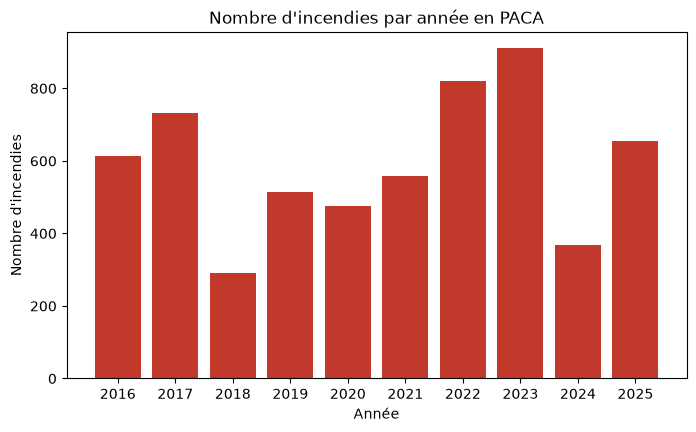

In [19]:
par_annee = incendies.groupby("Année").size()
graphiques.barres(par_annee, "Nombre d'incendies par année en PACA", "Année", "Nombre d'incendies",
                  fichier="sorties/incendies_par_annee.png")

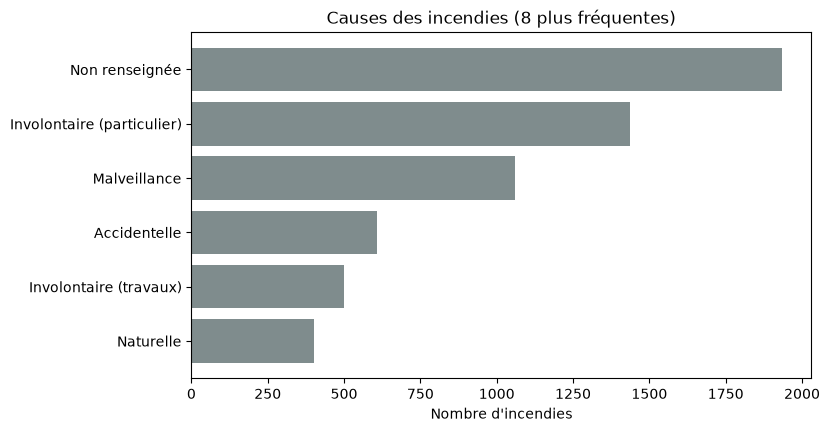

In [20]:
causes = incendies["Nature"].fillna("Non renseignée").value_counts().head(8)
graphiques.barres(causes, "Causes des incendies (8 plus fréquentes)", "Nombre d'incendies", "",
                  couleur="#7f8c8d", horizontal=True, fichier="sorties/incendies_causes.png")

### 4.2 Les casernes

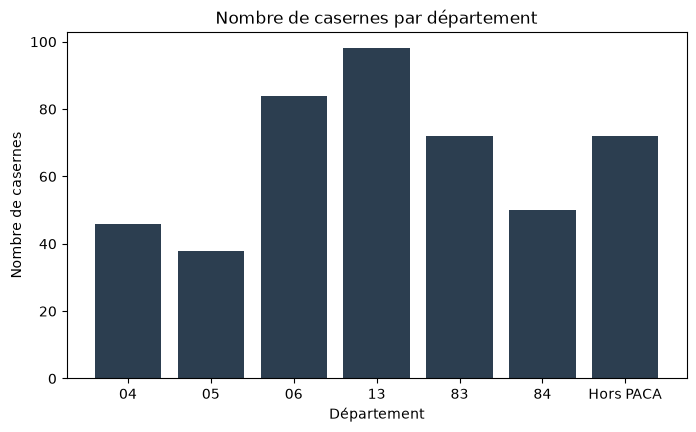

In [21]:
# département de chaque caserne (celles de la marge de 20 km sont "Hors PACA")
casernes_dep = gpd.sjoin(casernes, communes[[p.COL_DEP, "geometry"]], how="left", predicate="within")
casernes_dep[p.COL_DEP] = casernes_dep[p.COL_DEP].fillna("Hors PACA")
nb_casernes_dep = casernes_dep[p.COL_DEP].value_counts().sort_index()
graphiques.barres(nb_casernes_dep, "Nombre de casernes par département", "Département", "Nombre de casernes",
                  couleur="#2c3e50", fichier="sorties/casernes_par_departement.png")

### 4.3 Les forêts

In [22]:
tableau_forets = forets.groupby("lib3_19").agg(
    nb_forets=("id_foret", "count"),
    surface_totale_ha=("surface_ha", "sum"),
    surface_mediane_ha=("surface_ha", "median")
)
tableau_forets.to_csv("sorties/types_forets.csv")
print("Surface forestière totale (ha) :", round(forets["surface_ha"].sum()))
graphiques.joli_tableau(tableau_forets, "Les forêts de PACA par type", couleurs="Greens")

Surface forestière totale (ha) : 1864507


,nb_forets,surface_totale_ha,surface_mediane_ha
lib3_19,,,
Foret et vegetation arbustive en mutation,"20,572.0","95,003.7",2.2
Forets de coniferes,"18,793.0","502,915.2",3.8
Forets de feuillus,"17,293.0","475,167.2",3.6
Forets melangees,"36,278.0","555,268.2",3.3
Landes et broussailles,"16,456.0","151,976.0",2.5
Pelouses et paturages naturels,"8,053.0","84,176.6",3.2


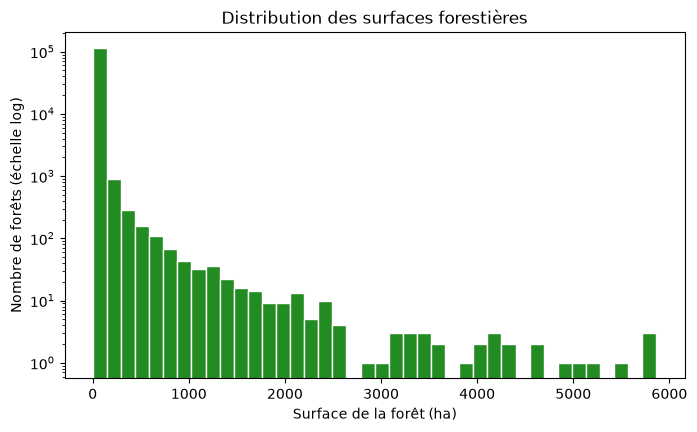

In [23]:
graphiques.histogramme(forets["surface_ha"], "Distribution des surfaces forestières",
                       "Surface de la forêt (ha)", "Nombre de forêts (échelle log)",
                       couleur="forestgreen", log=True, fichier="sorties/surfaces_forets.png")

## 5. Enregistrement des données préparées

J'enregistre les tables prêtes à l'emploi dans un GeoPackage (`sorties/donnees_preparees.gpkg`), une couche par table. Le notebook 2 les relira directement, sans refaire toute la préparation.

In [24]:
fichier_prep = "sorties/donnees_preparees.gpkg"
communes.to_file(fichier_prep, layer="communes", driver="GPKG")
casernes.to_file(fichier_prep, layer="casernes", driver="GPKG")
forets.to_file(fichier_prep, layer="forets", driver="GPKG")
points_forets.to_file(fichier_prep, layer="points_forets", driver="GPKG")

incendies.to_csv("sorties/incendies_paca.csv", sep=";", index=False)
nb_incendies.to_csv("sorties/nb_incendies_par_commune.csv", sep=";", index=False)
print("Données préparées enregistrées !")

Données préparées enregistrées !
